<a href="https://colab.research.google.com/github/stefa54sm-ai/Analisi-DataSet/blob/main/Analisi_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
ANALISI DEL DATASET NATICUSdroid (Android Permissions)

In [1]:
# installazione delle librerie necessarie
!pip install ucimlrepo matplotlib scikit-learn seaborn numpy pandas

In [2]:
from ucimlrepo import fetch_ucirepo

# Messaggio per confermare l'inizio dell'operazione
print("Scaricamento del dataset in corso...")

# Scarichiamo il dataset originale tramite il suo ID univoco (519)
NATICUSdroid = fetch_ucirepo(id=722)

print("Dataset scaricato con successo!")

Scaricamento del dataset in corso...
Dataset scaricato con successo!


In [4]:
# Organizziamo i dati in tabelle chiamate DataFrame
# X contiene le caratteristiche (la presenza o meno dei permessi nelle app)
X = NATICUSdroid.data.features

# y contiene l'etichetta da prevedere (il risultato: app benigna o malware)
y = NATICUSdroid.data.targets

print("Dati estratti e pronti per l'analisi.")

Dati estratti e pronti per l'analisi.


In [5]:
# Visualizziamo le informazioni generali sul dataset per capire da dove viene
print("--- Informazioni Generali (Metadata) ---")
print(NATICUSdroid.metadata)

--- Informazioni Generali (Metadata) ---
{'uci_id': 722, 'name': 'NATICUSdroid (Android Permissions)', 'repository_url': 'https://archive.ics.uci.edu/dataset/722/naticusdroid+android+permissions+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/722/data.csv', 'abstract': 'Contains permissions extracted from more than 29000 benign & malware Android apps released between 2010-2019.', 'area': 'Computer Science', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 29333, 'num_features': 86, 'feature_types': [], 'demographics': [], 'target_col': ['Result'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2021, 'last_updated': 'Tue Apr 09 2024', 'dataset_doi': '10.24432/C5FS64', 'creators': ['Akshay Mathur'], 'intro_paper': {'ID': 122, 'type': 'NATIVE', 'title': 'NATICUSdroid: A malware detection framework for Android using native and custom permissions', 'authors': 'A. Mathur, Laxmi M. Podila,

In [6]:
# Visualizziamo la descrizione di ogni singola colonna
print("\n--- Dettaglio delle Variabili ---")
print(NATICUSdroid.variables)


--- Dettaglio delle Variabili ---
                                                 name     role     type  \
0                     android.permission.GET_ACCOUNTS  Feature  Integer   
1    com.sonyericsson.home.permission.BROADCAST_BADGE  Feature  Integer   
2                     android.permission.READ_PROFILE  Feature  Integer   
3                  android.permission.MANAGE_ACCOUNTS  Feature  Integer   
4              android.permission.WRITE_SYNC_SETTINGS  Feature  Integer   
..                                                ...      ...      ...   
82  com.google.android.finsky.permission.BIND_GET_...  Feature  Integer   
83  com.huawei.android.launcher.permission.READ_SE...  Feature  Integer   
84                        android.permission.READ_SMS  Feature  Integer   
85          android.permission.PROCESS_INCOMING_CALLS  Feature  Integer   
86                                             Result   Target  Integer   

   demographic description units missing_values  
0         None

In [12]:
# Mostriamo le prime 5 righe della tabella X per vedere i valori numerici
print("Anteprima dei dati:")
X.head()

Anteprima dei dati:


,android.permission.GET_ACCOUNTS,com.sonyericsson.home.permission.BROADCAST_BADGE,android.permission.READ_PROFILE,android.permission.MANAGE_ACCOUNTS,android.permission.WRITE_SYNC_SETTINGS,android.permission.READ_EXTERNAL_STORAGE,android.permission.RECEIVE_SMS,com.android.launcher.permission.READ_SETTINGS,android.permission.WRITE_SETTINGS,com.google.android.providers.gsf.permission.READ_GSERVICES,...,android.permission.CLEAR_APP_CACHE,com.android.launcher.permission.UNINSTALL_SHORTCUT,com.sec.android.iap.permission.BILLING,com.htc.launcher.permission.UPDATE_SHORTCUT,com.sec.android.provider.badge.permission.WRITE,android.permission.ACCESS_NETWORK_STATE,com.google.android.finsky.permission.BIND_GET_INSTALL_REFERRER_SERVICE,com.huawei.android.launcher.permission.READ_SETTINGS,android.permission.READ_SMS,android.permission.PROCESS_INCOMING_CALLS
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,0,0,0


Per prima cosa verifichiamo se il dataset che vogliamo analizzare è bilanciato oppure no. Ovvero, verifichiamo se il numero di malware e di app benigne all'interno del dataset è simile.

/tmp/ipykernel_536/3551224278.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Legenda', palette=['#4C72B0', '#DD8452'])


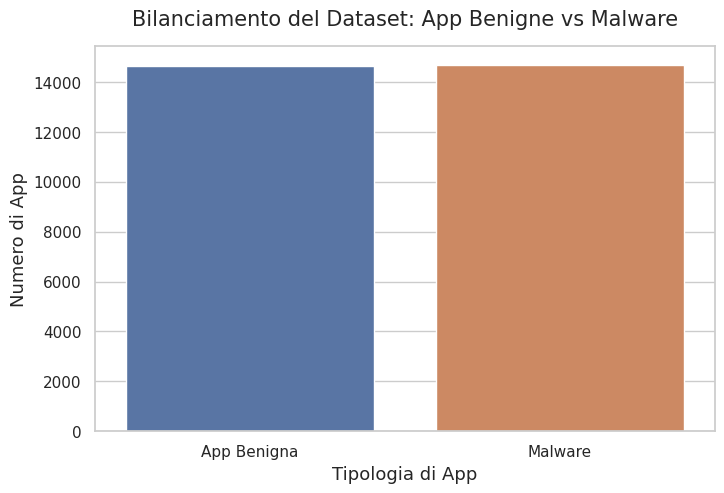

In [19]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Legenda', palette=['#4C72B0', '#DD8452'])
plt.title('Bilanciamento del Dataset: App Benigne vs Malware', fontsize=15, pad=15)
plt.xlabel('Tipologia di App', fontsize=13)
plt.ylabel('Numero di App', fontsize=13)
plt.show()

Ora che abbiamo capito che il dataet è bilanciato, la prima cosa che vogliamo capire è se i malware chiedono più permessi rispetto alle app normali (benigne). In poche parole mettiamo a confronto il numero totale di permessi richiesti dalle app sicure (blu) rispetto ai malware (arancione)

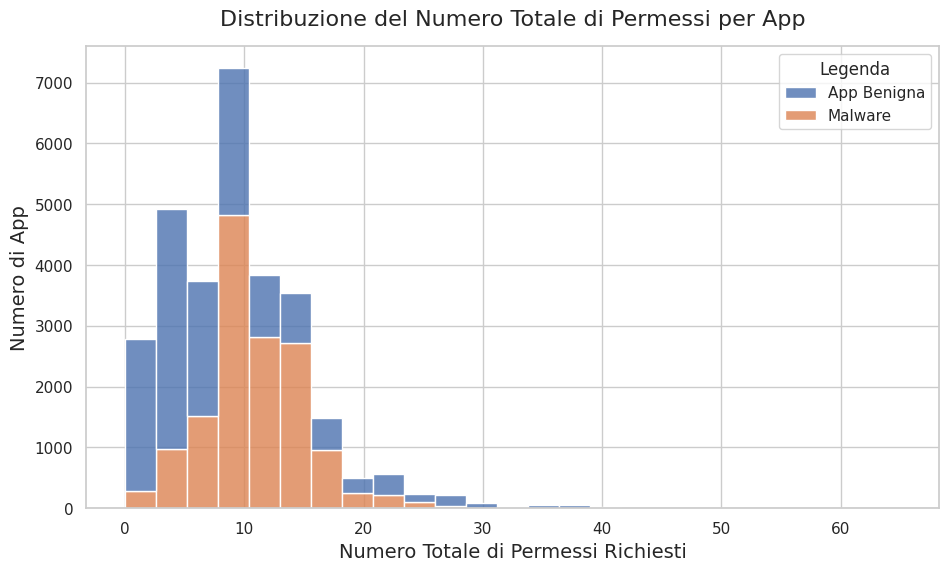

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Uniamo le caratteristiche (X) e il risultato (y) in un'unica tabella
df = pd.concat([X, y], axis=1)

# Mappiamo i valori della colonna Result per avere etichette chiare nella legenda
# 0 = App Benigna (blu), 1 = Malware (arancione/rosso)
df['Legenda'] = df['Result'].map({0: 'App Benigna', 1: 'Malware'})

# Calcoliamo una nuova colonna: quanti permessi richiede in totale ciascuna app?
# Sommiamo i valori (1) di tutte le colonne dei permessi per ogni riga
df['total_permissions'] = X.sum(axis=1)

# Impostiamo lo stile pulito
sns.set_theme(style="whitegrid")
plt.figure(figsize=(11, 6))

# Creiamo l'istogramma suddividendo i colori in base al target ('Result': malware vs benigno)
# 'multiple="stack"' impila le barre per vedere il totale complessivo e la proporzione
sns.histplot(
    data=df,
    x='total_permissions',
    hue='Legenda',          # Colora diversamente in base al risultato (malware o no)
    bins=25,
    multiple="stack",
    palette=['#4C72B0', '#DD8452'],
    alpha=0.8
)

# Aggiungiamo titolo ed etichette
plt.title('Distribuzione del Numero Totale di Permessi per App', fontsize=16, pad=15)
plt.xlabel('Numero Totale di Permessi Richiesti', fontsize=14)
plt.ylabel('Numero di App', fontsize=14)

# Mostriamo il grafico
plt.show()
